# Estatística sobre o agente — AO1 da D3

O conjunto `ao1/casos-ams-60.csv` contém 60 casos rotulados entre 2026-03-02 e 2026-04-10: 33 `seguir_operando`, 14 `parar_para_manutencao` e 13 `inspecionar_antes_de_operar`; 20 casos têm `falhou_depois = 1`. O arquivo não documenta amostragem aleatória de ordens reais, então trato os registros como conjunto de avaliação, não como retrato comprovado da frota.

- **Origem:** os 60 registros rotulados de `ao1/casos-ams-60.csv`; a proveniência operacional individual não está documentada no arquivo.
- **Variante A:** linha de base da D2, `decidir()` em `src/ams/baseline.py`.
- **Variante B:** mantém as regras de parada e histórico da A; acrescenta inspeção preventiva quando `horas_desde_manutencao > 180`. É uma hipótese experimental, não uma política operacional validada.
- **Métrica observável:** acerto exato da ação rotulada. A taxa primária de retrabalho em ordens reais acompanhadas por 30 dias continua sem medição; a acurácia abaixo é apenas uma proxy.

In [1]:
from pathlib import Path
import runpy
import sys

ROOT = next(parent for parent in (Path.cwd(), *Path.cwd().parents)
            if (parent / "ao1" / "ao1.py").is_file())
AO1_DIR = ROOT / "ao1"
sys.path.insert(0, str(ROOT / "src"))
ao1_execucao = runpy.run_path(str(AO1_DIR / "ao1.py"))

60 casos
A acertou 47 · B acertou 43
discordam no C05 · A: 1 · B: 0
discordam no C26 · A: 1 · B: 0
discordam no C31 · A: 1 · B: 0
discordam no C39 · A: 0 · B: 1
discordam no C51 · A: 0 · B: 1
discordam no C52 · A: 1 · B: 0
discordam no C56 · A: 1 · B: 0
discordam no C59 · A: 1 · B: 0
latência da variante A (µs) em 3000 decisões: p50 1.7 · p95 2.7 · média 1.5 · máximo 32.7
latência da variante B (µs) em 3000 decisões: p50 1.1 · p95 2.6 · média 1.4 · máximo 9.2


## As duas variantes e a latência

A acertou **47/60 (78,3%)** e B **43/60 (71,7%)**. Houve oito casos discordantes: A acertou seis que B errou; B acertou dois que A errou. A regra preventiva nova não melhorou a acurácia neste conjunto. Isso não prova que B seja pior em produção: são 60 casos de avaliação, e a regra de 180 horas ainda precisa de validação operacional.

Na execução registrada, a medição local em 3.000 decisões por variante encontrou A: **p50 1,7 µs; p95 2,7 µs**; B: **p50 1,1 µs; p95 2,6 µs**. São tempos apenas da função de decisão em Python, sem LLM, rede, leitura de dados ou intervenção humana. A média pode ser enganosa porque poucas pausas do sistema ou execuções de cauda longa a elevam; p50 e p95 mostram melhor o tempo típico e a cauda. Esses microssegundos não validam o limite operacional de 30 s.

# O meu dado, com rigor — relatório do Laboratório 03

Conjunto: `/home/luciano/CEDAGI/meu-projeto-integrador/ao1/casos-ams-60.csv` · 60 linhas · 9 variáveis

Medidas geradas pelo `medidas.py`: desvio padrão amostral (ddof=1),
quartis por interpolação linear, extremos pela regra da amplitude
interquartil — fora de 1,5 × a caixa (slide 24). As medidas são do
programa; as decisões são SUAS. Preencha todos os blocos `R:` e
confira com `python teste.py`.

## Medidas por variável

| variável | tipo | n | faltantes | média | mediana | desvio | Q1 | Q3 | AIQ | mín | máx |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| id_caso | categórica (60 valores; moda: C54) | 60 | 0 | — | — | — | — | — | — | — | — |
| data | categórica (30 valores; moda: 2026-03-04) | 60 | 0 | — | — | — | — | — | — | — | — |
| tipo_maquina | categórica (4 valores; moda: PRENSA) | 60 | 0 | — | — | — | — | — | — | — | — |
| idade_meses | numérica | 60 | 0 | 52.1833 | 53.0000 | 28.3067 | 36.0000 | 64.0000 | 28.0000 | 3.0000 | 216.0000 |
| temperatura_c | numérica | 60 | 0 | 65.7617 | 63.0000 | 7.1741 | 61.0000 | 66.6250 | 5.6250 | 58.0000 | 83.0000 |
| vibracao_mm_s | numérica | 60 | 0 | 4.3892 | 3.6500 | 1.9195 | 3.0000 | 5.5750 | 2.5750 | 2.0000 | 8.6000 |
| horas_desde_manutencao | numérica | 60 | 0 | 118.9667 | 107.5000 | 51.7399 | 85.0000 | 152.5000 | 67.5000 | 20.0000 | 230.0000 |
| acao_correta | categórica (3 valores; moda: seguir_operando) | 60 | 0 | — | — | — | — | — | — | — | — |
| falhou_depois | numérica | 60 | 0 | 0.3333 | 0.0000 | 0.4754 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | 1.0000 |

## Extremos marcados (fora de 1,5 × a caixa — slide 24)

### Extremos de `idade_meses` — 1 valor(es), limites [-6.0000; 106.0000]

| linha | valor |
|---:|---:|
| 12 | 216.0000 |

Decisão sobre ESTES extremos — manter ou remover, caso a caso,
com o motivo (slide 25: quem remove sem dizer, mente por omissão):

R:

### Extremos de `temperatura_c` — 10 valor(es), limites [52.5625; 75.0625]

| linha | valor |
|---:|---:|
| 2 | 81.5000 |
| 6 | 77.5000 |
| 13 | 79.2000 |
| 17 | 76.0000 |
| 21 | 80.0000 |
| 27 | 82.5000 |
| 34 | 79.5000 |
| 41 | 83.0000 |
| 43 | 79.0000 |
| 53 | 81.0000 |

Decisão sobre ESTES extremos — manter ou remover, caso a caso,
com o motivo (slide 25: quem remove sem dizer, mente por omissão):

R:


## Faltantes (os três mecanismos do slide 26)

Nenhuma variável tem valores faltantes.

## As quatro perguntas do slide 29

**1. Média e mediana se separam em alguma variável? Em qual?**

R:

**2. Quantos extremos foram marcados, e quantos você decidiu manter?**

R:

**3. Algum faltante parece do terceiro mecanismo?**

R:

**4. O que a análise da D1 não tinha visto?**

R:

## Comparação com a análise exploratória da D1

O que mudou de lá para cá — o que a análise de lá não tinha visto,
e o que estas decisões escritas mudam no conjunto que a D5 vai usar:

R:


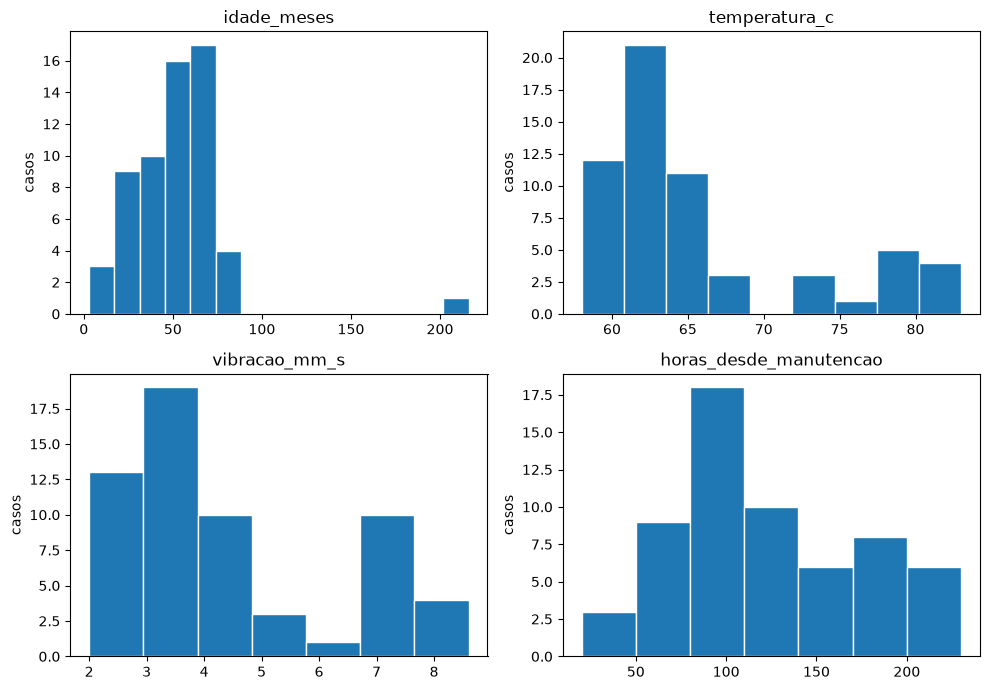

In [2]:
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

medidas_path = ROOT / "D3-03-estatistica-descritiva" / "medidas.py"
spec = importlib.util.spec_from_file_location("medidas_ao1", medidas_path)
medidas = importlib.util.module_from_spec(spec)
spec.loader.exec_module(medidas)
colunas, linhas = medidas.ler_csv(AO1_DIR / "casos-ams-60.csv")
resumos = [medidas.resumir_variavel(nome, [linha[i] for linha in linhas], len(linhas))
           for i, nome in enumerate(colunas)]
relatorio = medidas.gerar_relatorio(resumos, AO1_DIR / "casos-ams-60.csv", len(linhas))
(AO1_DIR / "relatorio-60.md").write_text(relatorio, encoding="utf-8")
display(Markdown(relatorio))

casos = pd.read_csv(AO1_DIR / "casos-ams-60.csv")
variaveis = ["idade_meses", "temperatura_c", "vibracao_mm_s", "horas_desde_manutencao"]
fig, eixos = plt.subplots(2, 2, figsize=(10, 7))
for eixo, nome in zip(eixos.flat, variaveis):
    eixo.hist(casos[nome], bins="auto", edgecolor="white")
    eixo.set_title(nome)
    eixo.set_ylabel("casos")
fig.tight_layout()
display(fig)
plt.close(fig)

## Decisões da análise exploratória

**Distribuições relevantes:** temperatura tem média 65,76 °C e mediana 63,00 °C; vibração, 4,39 mm/s e 3,65 mm/s; horas desde manutenção, 118,97 h e 107,50 h. A diferença entre média e mediana sugere cauda à direita, sobretudo em vibração e temperatura. As ações rotuladas são desbalanceadas (33 seguir, 14 parar e 13 inspecionar), por isso a acurácia total não descreve todos os riscos igualmente.

**Extremos:** o critério de 1,5 × AIQ marcou 11 observações: idade 216 meses (linha 12) e temperaturas nas linhas 2, 6, 13, 17, 21, 27, 34, 41, 43 e 53. Decido manter todas provisoriamente e conferir com registros de origem. A idade pode ser real; temperaturas altas podem ser condição crítica, não erro. Removê-las sem validação apagaria casos importantes e mudaria a avaliação do agente. Nenhum extremo foi marcado em vibração, horas de manutenção ou desfecho.

**Faltantes:** não há células faltantes; não se aplica hipótese MCAR/MAR/MNAR nem imputação.

## Intervalo por reamostragem

Como `comum/reamostragem.py` não está neste checkout, uso bootstrap percentil pareado nas 60 linhas, com **semente 20261114** e 20.000 reamostragens. Os intervalos são para acerto exato (proxy disponível), não para a taxa primária de retrabalho, que não pode ser calculada sem desfechos reais em 30 dias. A diferença B−A observada é −6,7 pontos percentuais; o intervalo inclui zero, portanto estes dados não demonstram uma diferença conclusiva.

In [3]:
import numpy as np
import pandas as pd

acertos = pd.read_csv(AO1_DIR / "acertos.csv")
acertos_a = acertos["linha_de_base"].to_numpy(dtype=int)
acertos_b = acertos["variante_b"].to_numpy(dtype=int)
semente = 20261114
reamostragens = 20_000
rng = np.random.default_rng(semente)
indices = rng.integers(0, len(acertos_a), size=(reamostragens, len(acertos_a)))
boot_a = acertos_a[indices].mean(axis=1)
boot_b = acertos_b[indices].mean(axis=1)
boot_diferenca = boot_b - boot_a
for nome, valores in (("A", boot_a), ("B", boot_b), ("B − A", boot_diferenca)):
    inferior, superior = np.quantile(valores, [0.025, 0.975])
    print(f"{nome}: estimativa {valores.mean():.3f}; IC bootstrap 95% [{inferior:.3f}, {superior:.3f}]")

A: estimativa 0.783; IC bootstrap 95% [0.683, 0.883]
B: estimativa 0.717; IC bootstrap 95% [0.600, 0.833]
B − A: estimativa -0.066; IC bootstrap 95% [-0.167, 0.017]


## Tamanho de amostra para detectar 5 pontos percentuais

O kit `comum/amostra.py` também não está presente; a célula seguinte reproduz uma aproximação normal para duas proporções. A taxa-base declarada é A = 47/60 = 0,7833; uso α = 0,05, poder = 80% e diferença-alvo = 0,05. Para o desenho pareado, a conta assume discordância de 8/60 observada no piloto; esse parâmetro é incerto com apenas 60 pares. A estimativa é **417 pares**. No desenho não pareado são **972 casos por variante** (1.944 no total). São aproximações de planejamento, não garantia de poder real.

Com 60 casos, não é honesto esperar distinguir com segurança um ganho de apenas 5 p.p. Para procurar esse efeito, seria necessário ampliar bastante a amostra, priorizando casos representativos e rótulos verificados. A expansão vale o custo se a decisão de adotar a variante tiver benefício operacional relevante e dados de qualidade suficientes.

In [4]:
from math import ceil, sqrt
from scipy.stats import norm

def casos_para_diferenca(taxa_base, diferenca, discordancia_pareada, alfa=0.05, poder=0.80):
    taxa_nova = taxa_base + diferenca
    if not 0 < taxa_base < 1 or not 0 < taxa_nova < 1:
        raise ValueError("as taxas devem ficar estritamente entre 0 e 1")
    z_alfa = norm.ppf(1 - alfa / 2)
    z_poder = norm.ppf(poder)
    media = (taxa_base + taxa_nova) / 2
    n_por_grupo = ceil((z_alfa * sqrt(2 * media * (1 - media))
                        + z_poder * sqrt(taxa_base * (1 - taxa_base)
                                         + taxa_nova * (1 - taxa_nova))) ** 2
                       / diferenca ** 2)
    q = discordancia_pareada
    if q <= diferenca ** 2:
        raise ValueError("discordância insuficiente para a aproximação pareada")
    n_pareado = ceil((z_alfa * sqrt(q) + z_poder * sqrt(q - diferenca ** 2)) ** 2
                     / diferenca ** 2)
    return n_pareado, n_por_grupo

taxa_base = float(acertos_a.mean())
discordancia = float(np.mean(acertos_a != acertos_b))
n_pareado, n_por_grupo = casos_para_diferenca(
    taxa_base=taxa_base, diferenca=0.05, discordancia_pareada=discordancia)
print(f"taxa-base={taxa_base:.4f}; discordância pareada observada={discordancia:.4f}")
print(f"pareado: {n_pareado} pares; não pareado: {n_por_grupo} por grupo ({2*n_por_grupo} no total)")

taxa-base=0.7833; discordância pareada observada=0.1333
pareado: 417 pares; não pareado: 972 por grupo (1944 no total)


## Correlação e causalidade

Temperatura e falha posterior têm correlação ponto-bisserial de Pearson **r = 0,601** e Spearman **ρ = 0,543**; a temperatura média é 71,81 °C nos 20 casos com falha e 62,74 °C nos 40 sem falha. Isso é associação, não causalidade. Explicações alternativas: (1) tipo de máquina, carga ou regime de operação pode afetar ambos; (2) viés de seleção, pois o arquivo não documenta amostragem aleatória e pode conter mais casos de alerta. A análise completa está em [`ao1/correlacao-causalidade.md`](../ao1/correlacao-causalidade.md).

In [5]:
from scipy.stats import pearsonr, spearmanr

temperatura = casos["temperatura_c"].to_numpy()
falha = casos["falhou_depois"].to_numpy()
r = pearsonr(temperatura, falha).statistic
rho = spearmanr(temperatura, falha).statistic
print(f"Pearson ponto-bisserial r={r:.3f}; Spearman rho={rho:.3f}")
print(casos.groupby("falhou_depois")["temperatura_c"].agg(["count", "mean", "median"]))

Pearson ponto-bisserial r=0.601; Spearman rho=0.543
               count     mean  median
falhou_depois                        
0                 40  62.7375   61.75
1                 20  71.8100   72.50


## Comparação pareada descritiva

Como A e B foram avaliadas nas mesmas 60 linhas, a comparação preserva o pareamento: oito casos discordam; A vence em seis e B em dois. Isso corresponde a −4 acertos líquidos para B (−6,7 p.p.). O intervalo bootstrap pareado da diferença inclui zero; com esta amostra, a conclusão honesta é que não há evidência suficiente de melhoria. A comparação inferencial completa fica para o laboratório do segundo sábado.